<a href="https://colab.research.google.com/github/tasfiii/20_Newsgroups_Classifier-ML-Lab-/blob/main/20_newsgroups_ML_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

# 1. Print df_list shape and head
print("=== df_list Shape ===")
print(df_list.shape)
print("\n=== df_list Head ===")
print(df_list.head())

# 2. Print df category counts
print("\n=== df['category'] Value Counts ===")
print(df['category'].value_counts())

# 3. Print first 20 lines of alt.atheism.txt
atheism_path = os.path.join(target_path, 'alt.atheism.txt')
print(f"\n=== First 20 lines of {atheism_path} ===")
try:
    with open(atheism_path, 'r', encoding='utf-8', errors='ignore') as f:
        for i in range(20):
            line = f.readline()
            if not line:
                break
            print(line, end='')
except Exception as e:
    print(f"Error reading file: {e}")

=== df_list Shape ===


NameError: name 'df_list' is not defined

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
try:
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print(f"Mount failed: {e}\n")

# Correct path with 'ML lab'
target_path = '/content/drive/MyDrive/ML lab/20_Newsgroups'

# List the files in the directory if it exists
if os.path.exists(target_path):
    files = os.listdir(target_path)
    print(f"\nFiles in {target_path}:")
    for file in files:
        print(file)
else:
    print(f"\nThe directory {target_path} does not exist. Checking if 'ML lab' exists:")
    ml_lab_path = '/content/drive/MyDrive/ML lab'
    if os.path.exists(ml_lab_path):
        print(f"'ML lab' folder exists. Contents of 'ML lab':")
        for item in os.listdir(ml_lab_path):
            print(item)
    else:
        print("'ML lab' folder not found.")

Mounted at /content/drive

Files in /content/drive/MyDrive/ML lab/20_Newsgroups:
alt.atheism.txt
comp.graphics.txt
comp.os.ms-windows.misc.txt
comp.sys.ibm.pc.hardware.txt
comp.sys.mac.hardware.txt
comp.windows.x.txt
list.csv
misc.forsale.txt
rec.autos.txt
rec.motorcycles.txt
rec.sport.baseball.txt
rec.sport.hockey.txt
sci.crypt.txt
sci.electronics.txt
sci.med.txt
sci.space.txt
soc.religion.christian.txt
talk.politics.guns.txt
talk.politics.mideast.txt
talk.politics.misc.txt
talk.religion.misc.txt


In [ ]:
import os

atheism_path = os.path.join(target_path, 'alt.atheism.txt')

# Count lines starting with 'From:'
from_count = 0
with open(atheism_path, 'r', encoding='utf-8', errors='ignore') as f:
    for line in f:
        if line.startswith('From:'):
            from_count += 1

print(f"Total lines starting with 'From:': {from_count}\n")

# Print the first 60 lines
print("=== First 60 lines of alt.atheism.txt ===")
with open(atheism_path, 'r', encoding='utf-8', errors='ignore') as f:
    for i in range(60):
        line = f.readline()
        if not line:
            break
        print(f"{i+1:02d}: {line}", end='')

Total lines starting with 'From:': 2409

=== First 60 lines of alt.atheism.txt ===
01: From: mathew <mathew@mantis.co.uk>
02: Subject: Alt.Atheism FAQ: Atheist Resources
03: 
04: Archive-name: atheism/resources
05: Alt-atheism-archive-name: resources
06: Last-modified: 11 December 1992
07: Version: 1.0
08: 
09:                               Atheist Resources
10: 
11:                       Addresses of Atheist Organizations
12: 
13:                                      USA
14: 
15: FREEDOM FROM RELIGION FOUNDATION
16: 
17: Darwin fish bumper stickers and assorted other atheist paraphernalia are
18: available from the Freedom From Religion Foundation in the US.
19: 
20: Write to:  FFRF, P.O. Box 750, Madison, WI 53701.
21: Telephone: (608) 256-8900
22: 
23: EVOLUTION DESIGNS
24: 
25: Evolution Designs sell the "Darwin fish".  It's a fish symbol, like the ones
26: Christians stick on their cars, but with feet and the word "Darwin" written
27: inside.  The deluxe moulded 3D plastic fish is

In [ ]:
import os
import pandas as pd

target_path = '/content/drive/MyDrive/ML lab/20_Newsgroups'
data = []

for file in os.listdir(target_path):
    if file.endswith('.txt'):
        file_path = os.path.join(target_path, file)
        category = file.replace('.txt', '')
        try:
            with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
                lines = f.readlines()

            current_post = []
            for line in lines:
                # If a line starts with 'From:', it signals the start of a new post
                if line.startswith('From:'):
                    if current_post:
                        post_text = "".join(current_post).strip()
                        if post_text:
                            data.append({'text': post_text, 'category': category})
                    current_post = [line]
                else:
                    current_post.append(line)

            # Append the last post of the file if it exists
            if current_post:
                post_text = "".join(current_post).strip()
                if post_text:
                    data.append({'text': post_text, 'category': category})

        except Exception as e:
            print(f"Error reading {file}: {e}")

# Create the reconstructed DataFrame
df = pd.DataFrame(data)

# Print shape and category value counts
print("=== Rebuilt DataFrame Shape ===")
print(df.shape)
print("\n=== Category Value Counts ===")
print(df['category'].value_counts())

=== Rebuilt DataFrame Shape ===
(39302, 2)

=== Category Value Counts ===
category
comp.graphics               2501
alt.atheism                 2409
sci.crypt                   2009
soc.religion.christian      2005
rec.sport.hockey            2003
sci.space                   1995
rec.motorcycles             1993
comp.sys.ibm.pc.hardware    1993
rec.sport.baseball          1993
rec.autos                   1991
comp.os.ms-windows.misc     1985
sci.med                     1985
comp.windows.x              1977
sci.electronics             1977
misc.forsale                1955
talk.politics.mideast       1937
comp.sys.mac.hardware       1931
talk.politics.guns          1829
talk.politics.misc          1571
talk.religion.misc          1263
Name: count, dtype: int64


In [ ]:
# 1. Check for null or empty strings in df
null_count = df['text'].isnull().sum()
empty_string_count = (df['text'].str.strip() == '').sum()

print(f"Number of null values in 'text': {null_count}")
print(f"Number of empty strings in 'text': {empty_string_count}\n")

# 2. Print category and first 300 characters of the first 3 posts
print("=== First 3 Posts in df ===")
for idx, row in df.head(3).iterrows():
    print(f"Post #{idx + 1} | Category: {row['category']}")
    print("-" * 50)
    print(row['text'][:300] + ("..." if len(row['text']) > 300 else ""))
    print("=" * 50 + "\n")

Number of null values in 'text': 0
Number of empty strings in 'text': 0

=== First 3 Posts in df ===
Post #1 | Category: alt.atheism
--------------------------------------------------
From: mathew <mathew@mantis.co.uk>
Subject: Alt.Atheism FAQ: Atheist Resources

Archive-name: atheism/resources
Alt-atheism-archive-name: resources
Last-modified: 11 December 1992
Version: 1.0

                              Atheist Resources

                      Addresses of Atheist Organizations
...

Post #2 | Category: alt.atheism
--------------------------------------------------
From: mathew <mathew@mantis.co.uk>
Subject: Alt.Atheism FAQ: Introduction to Atheism

Archive-name: atheism/introduction
Alt-atheism-archive-name: introduction
Last-modified: 5 April 1993
Version: 1.2

-----BEGIN PGP SIGNED MESSAGE-----

                          An Introduction to Atheism
         ...

Post #3 | Category: alt.atheism
--------------------------------------------------
From: I3150101@dbstu1.rz.tu-bs.de (Bened

In [ ]:
import re

def clean_post_text(text):
    # 1. Remove email addresses
    text = re.sub(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b', '', text)

    # 2. Split lines to strip common headers and PGP markers
    lines = text.split('\n')
    cleaned_lines = []
    for line in lines:
        # Skip header/metadata lines
        if any(line.strip().startswith(header) for header in [
            'From:', 'Subject:', 'Archive-name:', 'Alt-atheism-archive-name:', 'Last-modified:', 'Version:'
        ]):
            continue
        # Skip PGP boundary markers
        if any(marker in line for marker in ['-----BEGIN PGP', '-----END PGP']):
            continue
        cleaned_lines.append(line)

    # Reconstruct text
    text = "\n".join(cleaned_lines)

    # 3. Lowercase
    text = text.lower()

    # 4. Collapse extra whitespace (including newlines and spaces)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Create the clean_text column
df['clean_text'] = df['text'].apply(clean_post_text)

# Print the first 350 characters of the first 2 cleaned posts
print("=== Cleaned Posts Preview ===\n")
for idx, row in df.head(2).iterrows():
    print(f"Post #{idx + 1} | Category: {row['category']}")
    print("-" * 50)
    print(row['clean_text'][:350] + ("..." if len(row['clean_text']) > 350 else ""))
    print("=" * 50 + "\n")

=== Cleaned Posts Preview ===

Post #1 | Category: alt.atheism
--------------------------------------------------
atheist resources addresses of atheist organizations usa freedom from religion foundation darwin fish bumper stickers and assorted other atheist paraphernalia are available from the freedom from religion foundation in the us. write to: ffrf, p.o. box 750, madison, wi 53701. telephone: (608) 256-8900 evolution designs evolution designs sell the "dar...

Post #2 | Category: alt.atheism
--------------------------------------------------
an introduction to atheism by mathew <> this article attempts to provide a general introduction to atheism. whilst i have tried to be as neutral as possible regarding contentious issues, you should always remember that this document represents only one viewpoint. i would encourage you to read widely and draw your own conclusions; some relevant book...



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Identify and drop empty clean_text rows
empty_clean_mask = df['clean_text'].str.strip() == ''
empty_count = empty_clean_mask.sum()
print(f"Number of rows with empty 'clean_text': {empty_count}")

if empty_count > 0:
    df = df[~empty_clean_mask].reset_index(drop=True)
    print(f"Dropped {empty_count} rows. New DataFrame shape: {df.shape}")
else:
    print("No empty 'clean_text' rows found.")

# 2. Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['category'],
    test_size=0.20,
    random_state=42,
    stratify=df['category']
)

print(f"\nTraining set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")

# 3. Fit TfidfVectorizer on training text and transform it
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"\nTF-IDF Training Matrix shape: {X_train_tfidf.shape}")
print(f"TF-IDF Testing Matrix shape: {X_test_tfidf.shape}")

Number of rows with empty 'clean_text': 102
Dropped 102 rows. New DataFrame shape: (39200, 3)

Training set size: 31360
Testing set size: 7840

TF-IDF Training Matrix shape: (31360, 163014)
TF-IDF Testing Matrix shape: (7840, 163014)


In [ ]:
import numpy as np
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 1. Initialize and train the Multinomial Naive Bayes model
model = MultinomialNB(alpha=1.0)
model.fit(X_train_tfidf, y_train)

# 2. Predict on test data
y_pred = model.predict(X_test_tfidf)
y_prob = model.predict_proba(X_test_tfidf)

# 3. Print hyperparameters and general evaluation metrics
print("=== Model Hyperparameters ===")
print(model.get_params())

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')

print(f"\nTest Accuracy: {accuracy:.4f}")
print(f"Test Macro F1-score: {macro_f1:.4f}")

# 4. Print detailed classification report
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

# 5. Extract top 3 probabilities for the first 3 test samples
classes = model.classes_
print("=== Top 3 Predicted Probabilities for the First 3 Test Samples ===")
for idx in range(3):
    true_label = y_test.iloc[idx]
    predicted_label = y_pred[idx]
    probs = y_prob[idx]

    # Get indices of top 3 classes sorted by probability in descending order
    top_indices = np.argsort(probs)[::-1][:3]

    print(f"\nSample #{idx + 1} | True: {true_label} | Predicted: {predicted_label}")
    print("Top 3 Predictions:")
    for rank, class_idx in enumerate(top_indices, 1):
        print(f"  {rank}. {classes[class_idx]}: {probs[class_idx]:.4%}")

=== Model Hyperparameters ===
{'alpha': 1.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}

Test Accuracy: 0.9088
Test Macro F1-score: 0.8855

=== Classification Report ===
                          precision    recall  f1-score   support

             alt.atheism       0.62      1.00      0.76       481
           comp.graphics       0.83      0.97      0.89       500
 comp.os.ms-windows.misc       0.96      0.92      0.94       397
comp.sys.ibm.pc.hardware       0.87      0.95      0.91       399
   comp.sys.mac.hardware       1.00      0.96      0.98       385
          comp.windows.x       0.98      0.84      0.91       395
            misc.forsale       0.97      0.86      0.91       391
               rec.autos       0.98      0.95      0.97       397
         rec.motorcycles       1.00      0.98      0.99       398
      rec.sport.baseball       0.99      0.99      0.99       399
        rec.sport.hockey       0.99      0.99      0.99       400
               sci.

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 1. Initialize and train the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, C=1.0, penalty='l2', random_state=42)
lr_model.fit(X_train_tfidf, y_train)

# 2. Predict on test data
y_pred_lr = lr_model.predict(X_test_tfidf)
y_prob_lr = lr_model.predict_proba(X_test_tfidf)

# 3. Print hyperparameters and evaluation metrics
print("=== Logistic Regression Hyperparameters ===")
print(lr_model.get_params())

accuracy_lr = accuracy_score(y_test, y_pred_lr)
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f"\nTest Accuracy: {accuracy_lr:.4f}")
print(f"Test Macro F1-score: {macro_f1_lr:.4f}")

# 4. Print detailed classification report
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred_lr))

# 5. Extract top 3 probabilities for the first 3 test samples
classes_lr = lr_model.classes_
print("=== Top 3 Predicted Probabilities for the First 3 Test Samples ===")
for idx in range(3):
    true_label = y_test.iloc[idx]
    predicted_label = y_pred_lr[idx]
    probs = y_prob_lr[idx]

    # Get indices of top 3 classes sorted by probability in descending order
    top_indices = np.argsort(probs)[::-1][:3]

    print(f"\nSample #{idx + 1} | True: {true_label} | Predicted: {predicted_label}")
    print("Top 3 Predictions:")
    for rank, class_idx in enumerate(top_indices, 1):
        print(f"  {rank}. {classes_lr[class_idx]}: {probs[class_idx]:.4%}")

=== Logistic Regression Hyperparameters ===
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Test Accuracy: 0.9901
Test Macro F1-score: 0.9897

=== Classification Report ===
                          precision    recall  f1-score   support

             alt.atheism       0.99      0.99      0.99       481
           comp.graphics       0.99      0.99      0.99       500
 comp.os.ms-windows.misc       0.98      0.98      0.98       397
comp.sys.ibm.pc.hardware       0.97      0.98      0.98       399
   comp.sys.mac.hardware       0.99      1.00      0.99       385
          comp.windows.x       0.98      0.98      0.98       395
            misc.forsale       0.98      0.99      0.98       391
               rec.autos       1.00      1.00      1.00       3

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
import numpy as np

# Configure stratified 5-fold cross-validation
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Instantiate models
nb_clf = MultinomialNB(alpha=1.0)
lr_clf = LogisticRegression(max_iter=1000, C=1.0, penalty='l2', random_state=42)

print("Evaluating Multinomial Naive Bayes...")
nb_acc = cross_val_score(nb_clf, X_train_tfidf, y_train, cv=cv_splitter, scoring='accuracy')
nb_f1 = cross_val_score(nb_clf, X_train_tfidf, y_train, cv=cv_splitter, scoring='f1_macro')

print("Evaluating Logistic Regression...")
lr_acc = cross_val_score(lr_clf, X_train_tfidf, y_train, cv=cv_splitter, scoring='accuracy')
lr_f1 = cross_val_score(lr_clf, X_train_tfidf, y_train, cv=cv_splitter, scoring='f1_macro')

# Print Naive Bayes results
print("\n" + "="*60)
print("MULTINOMIAL NAIVE BAYES 5-FOLD CV")
print("="*60)
print(f"Accuracy Folds: {np.round(nb_acc, 4)}")
print(f"Mean Accuracy:  {nb_acc.mean():.4f} (+/- {nb_acc.std():.4f})")
print(f"F1 Macro Folds: {np.round(nb_f1, 4)}")
print(f"Mean F1 Macro:  {nb_f1.mean():.4f} (+/- {nb_f1.std():.4f})")

# Print Logistic Regression results
print("\n" + "="*60)
print("LOGISTIC REGRESSION 5-FOLD CV")
print("="*60)
print(f"Accuracy Folds: {np.round(lr_acc, 4)}")
print(f"Mean Accuracy:  {lr_acc.mean():.4f} (+/- {lr_acc.std():.4f})")
print(f"F1 Macro Folds: {np.round(lr_f1, 4)}")
print(f"Mean F1 Macro:  {lr_f1.mean():.4f} (+/- {lr_f1.std():.4f})")

Evaluating Multinomial Naive Bayes...
Evaluating Logistic Regression...

MULTINOMIAL NAIVE BAYES 5-FOLD CV
Accuracy Folds: [0.8992 0.8991 0.8988 0.9007 0.8999]
Mean Accuracy:  0.8995 (+/- 0.0007)
F1 Macro Folds: [0.8794 0.8766 0.8749 0.8815 0.8792]
Mean F1 Macro:  0.8783 (+/- 0.0023)

LOGISTIC REGRESSION 5-FOLD CV
Accuracy Folds: [0.9839 0.985  0.9861 0.9804 0.9834]
Mean Accuracy:  0.9838 (+/- 0.0019)
F1 Macro Folds: [0.9831 0.9839 0.9849 0.979  0.9822]
Mean F1 Macro:  0.9826 (+/- 0.0020)


In [ ]:
import pandas as pd

comparison_df = pd.DataFrame(
    {
        "Metric": [
            "Mean Accuracy",
            "Accuracy Std",
            "Mean F1 Macro",
            "F1 Macro Std",
        ],
        "Multinomial Naive Bayes": [
            round(nb_acc.mean(), 4),
            round(nb_acc.std(), 4),
            round(nb_f1.mean(), 4),
            round(nb_f1.std(), 4),
        ],
        "Logistic Regression": [
            round(lr_acc.mean(), 4),
            round(lr_acc.std(), 4),
            round(lr_f1.mean(), 4),
            round(lr_f1.std(), 4),
        ],
    }
)

# Optional formatted column showing "mean (+/- std)"
formatted_df = pd.DataFrame(
    {
        "Metric": ["Accuracy (5-Fold CV)", "F1 Macro (5-Fold CV)"],
        "Multinomial Naive Bayes": [
            f"{nb_acc.mean():.4f} (+/- {nb_acc.std():.4f})",
            f"{nb_f1.mean():.4f} (+/- {nb_f1.std():.4f})",
        ],
        "Logistic Regression": [
            f"{lr_acc.mean():.4f} (+/- {lr_acc.std():.4f})",
            f"{lr_f1.mean():.4f} (+/- {lr_f1.std():.4f})",
        ],
    }
)

print("=== Numeric Comparison Table ===")
display(comparison_df)

print("\n=== Paper-Ready Formatted Table ===")
display(formatted_df)

=== Numeric Comparison Table ===


,Metric,Multinomial Naive Bayes,Logistic Regression
0,Mean Accuracy,0.8995,0.9838
1,Accuracy Std,0.0007,0.0019
2,Mean F1 Macro,0.8783,0.9826
3,F1 Macro Std,0.0023,0.0020



=== Paper-Ready Formatted Table ===


,Metric,Multinomial Naive Bayes,Logistic Regression
0,Accuracy (5-Fold CV),0.8995 (+/- 0.0007),0.9838 (+/- 0.0019)
1,F1 Macro (5-Fold CV),0.8783 (+/- 0.0023),0.9826 (+/- 0.0020)


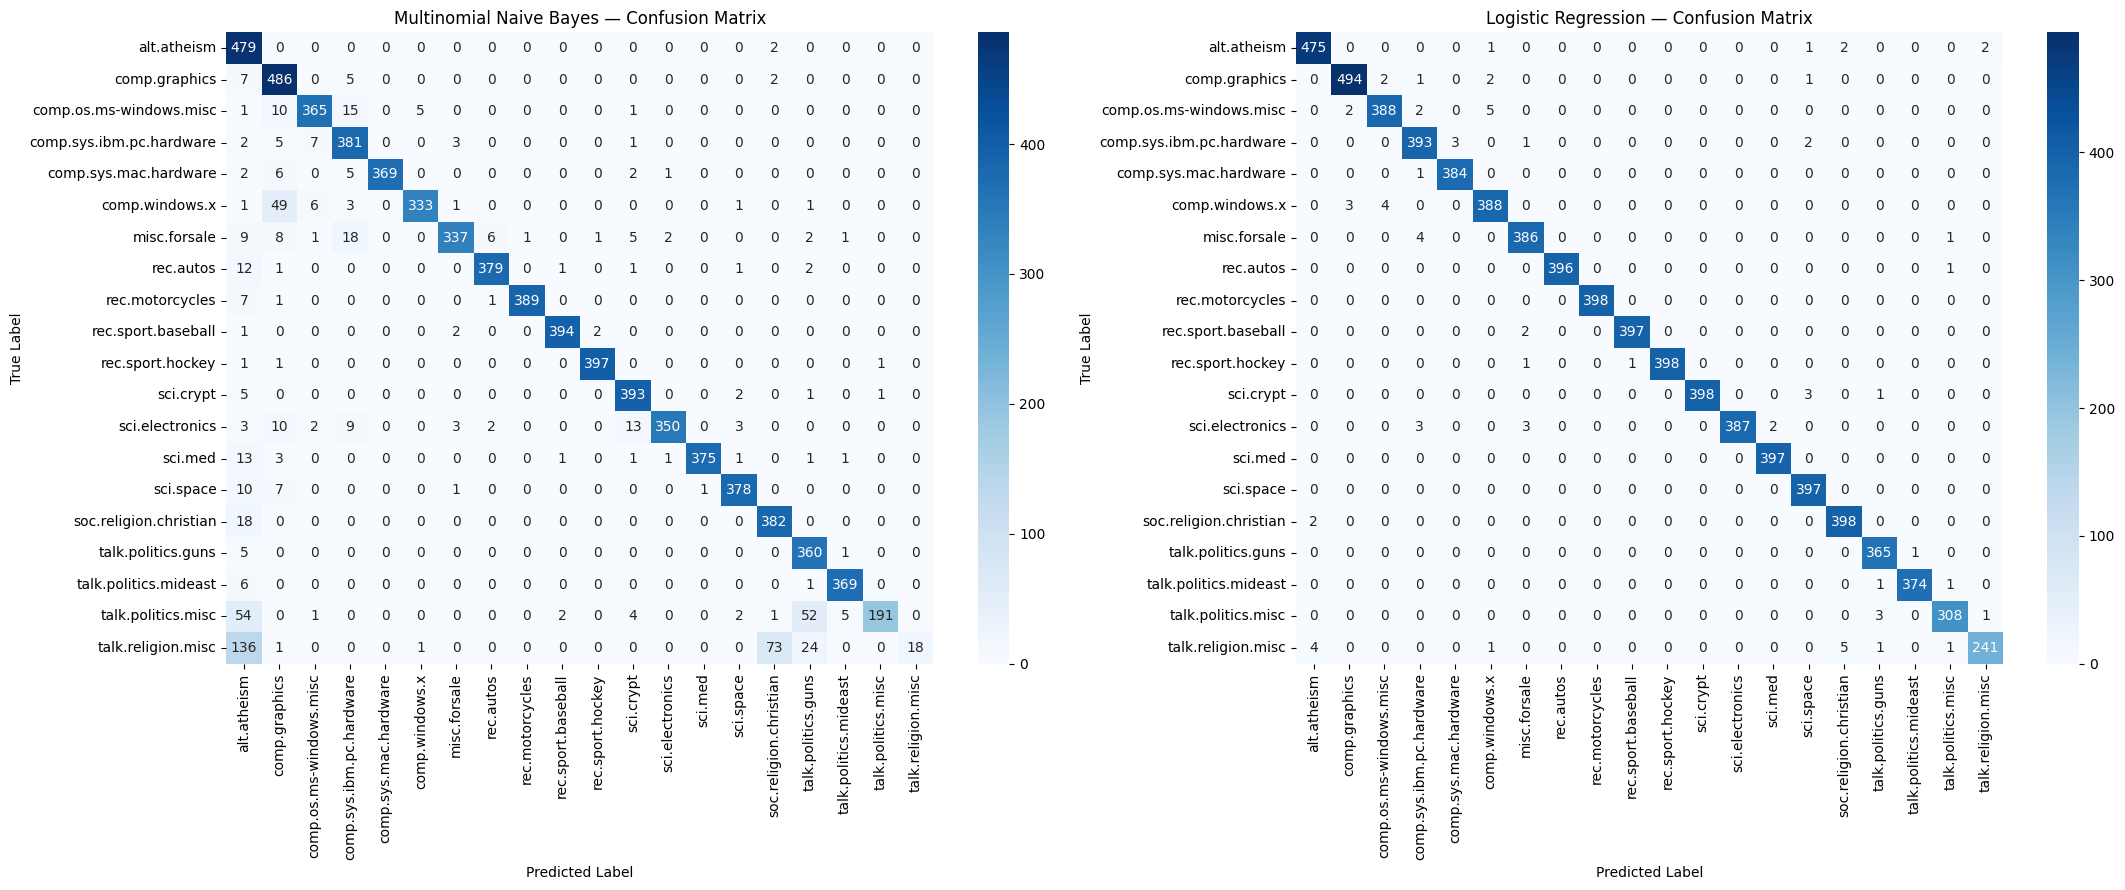

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import MultinomialNB

# Fit both models on the training set and predict on the test set
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train_tfidf, y_train)
nb_pred = nb_model.predict(X_test_tfidf)

lr_model = LogisticRegression(
    max_iter=1000, C=1.0, penalty="l2", random_state=42
)
lr_model.fit(X_train_tfidf, y_train)
lr_pred = lr_model.predict(X_test_tfidf)

# Determine class labels in consistent order
labels = sorted(list(set(y_test)))

cm_nb = confusion_matrix(y_test, nb_pred, labels=labels)
cm_lr = confusion_matrix(y_test, lr_pred, labels=labels)

# Plot side-by-side heatmaps
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0],
)
axes[0].set_title("Multinomial Naive Bayes — Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")
axes[0].tick_params(axis="x", rotation=90)
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1],
)
axes[1].set_title("Logistic Regression — Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].tick_params(axis="x", rotation=90)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

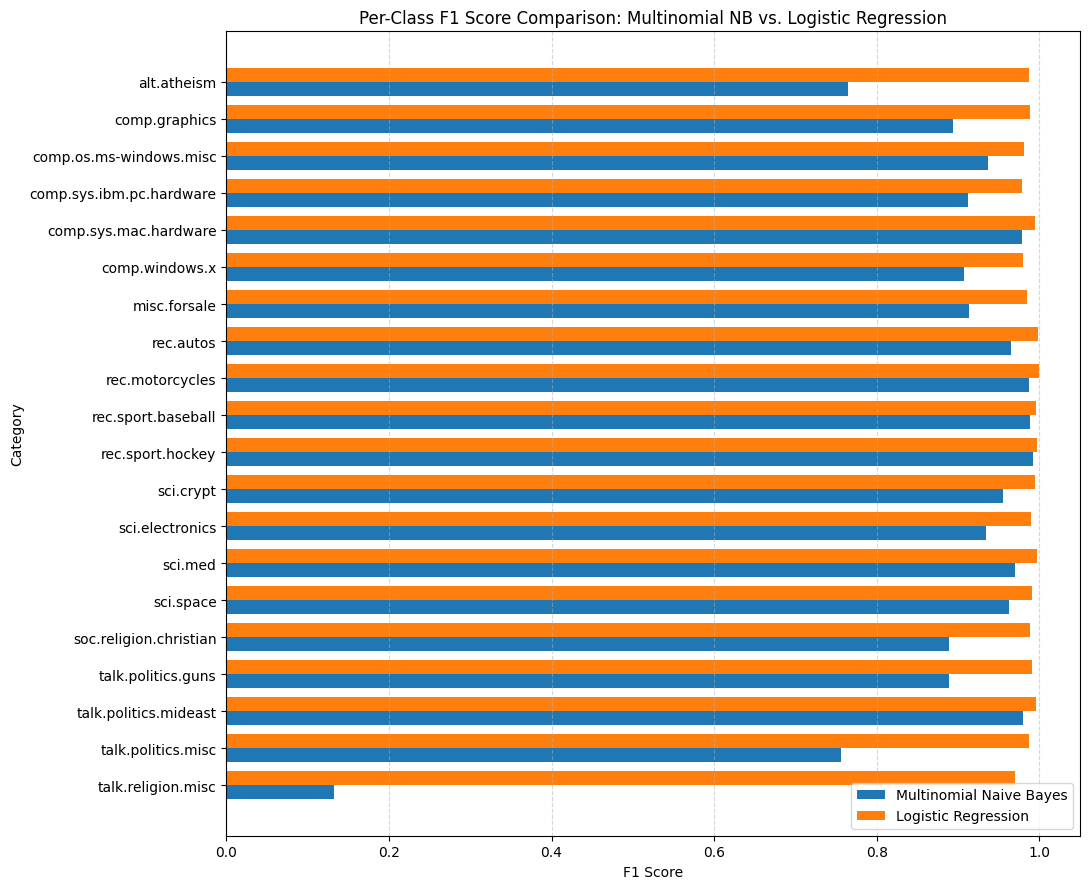

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score

# Ensure labels and test predictions are available
labels = sorted(list(set(y_test)))

# Compute per-class F1 scores in the exact same label order
f1_nb_per_class = f1_score(y_test, nb_pred, labels=labels, average=None)
f1_lr_per_class = f1_score(y_test, lr_pred, labels=labels, average=None)

# Plot horizontal grouped bar chart for clean category labels
y_pos = np.arange(len(labels))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(11, 9))

bars_nb = ax.barh(
    y_pos + bar_height / 2,
    f1_nb_per_class,
    height=bar_height,
    label="Multinomial Naive Bayes",
)
bars_lr = ax.barh(
    y_pos - bar_height / 2,
    f1_lr_per_class,
    height=bar_height,
    label="Logistic Regression",
)

ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.invert_yaxis()  # Top-to-bottom alphabetical order
ax.set_xlim(0, 1.05)
ax.set_xlabel("F1 Score")
ax.set_ylabel("Category")
ax.set_title("Per-Class F1 Score Comparison: Multinomial NB vs. Logistic Regression")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()